# Rentabilidad de operaciones de una estrategia sobre EUR/USD
### Clasificación con regresión logística, máquina de vectores de soporte y perceptrón multicapa con optimización bayesiana

|                |   |
:----------------|---|
| **Fecha**      | 2 de noviembre de 2026 |
| **Materia**    | Laboratorio de Aprendizaje Estadístico |

| Alumno | Expediente |
|--------|------------|
| Juan Pablo Moran | 753760 |
| Fer González | 748126  |

## Objetivos

### General
Estimar la probabilidad de que una operación de una estrategia de trading sobre el par EUR/USD termine siendo rentable después de costos, a partir de variables de volatilidad, actividad del mercado, estructura y características de la zona de entrada, comparando tres modelos de clasificación con hiperparámetros optimizados para identificar cuál distingue mejor las operaciones rentables de las que no lo son.

### Específicos
1. **Analizar el conjunto de datos** de operaciones generado a partir de precios históricos del EUR/USD (2020–2026): su origen, contenido, calidad y las transformaciones necesarias, verificando que los predictores solo usen información disponible al momento de la entrada.
2. **Diseñar un pipeline de preprocesamiento** (limpieza, transformación de variables categóricas y escalamiento) aplicado de la misma forma a los tres modelos y ajustado únicamente con datos de entrenamiento en cada fold.
3. **Ajustar una regresión logística con regularización**, una **SVM con kernel RBF** y un **perceptrón multicapa**, optimizando los hiperparámetros de cada uno mediante optimización bayesiana con procesos gaussianos.
4. **Comparar los modelos** con el ROC-AUC (media y desviación estándar en validación cruzada k-folds con $k=10$ sobre 2020–2024) y confirmar el resultado en un periodo de prueba posterior (2025–2026).
5. **Evaluar la utilidad práctica del mejor modelo**, comparando la tasa de acierto y la ganancia promedio por operación de todas las señales contra las señales que el modelo considera más probables de ser rentables.

## Marco teórico

### Regresión logística
La regresión logística modela la probabilidad de que una respuesta binaria $Y$ tome el valor 1 dados los predictores $X$. En lugar de ajustar una recta, pasa la combinación lineal de los predictores por la función sigmoide, que siempre queda entre 0 y 1:

$$ p(X) = P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \cdots + \beta_p X_p)}} $$

Despejando se obtiene que el logaritmo de los momios (*log-odds*) es lineal en los predictores:

$$ \ln\left(\frac{p(X)}{1-p(X)}\right) = \beta_0 + \beta_1 X_1 + \cdots + \beta_p X_p $$

Los coeficientes se estiman por máxima verosimilitud, lo que equivale a minimizar la entropía cruzada (*log-loss*):

$$ J(\vec{\beta}) = -\sum_{i=1}^n \left[ y_i \ln(\hat{p}(x_i)) + (1-y_i)\ln(1-\hat{p}(x_i)) \right] $$

Esta función es convexa, por lo que tiene un único mínimo global. La frontera de decisión ($p(X)=0.5$) es un hiperplano, es decir, el modelo solo separa clases de forma lineal en el espacio de los predictores.

**Regularización.** Igual que en Ridge y Lasso, se agrega una penalización a los coeficientes para reducir varianza y sobreajuste. En `sklearn` se controla con $C = 1/\lambda$ (un $C$ pequeño penaliza más) y con `l1_ratio`, que mezcla las penalizaciones L1 y L2 (*elastic net*):

$$ J_{reg}(\vec{\beta}) = J(\vec{\beta}) + \frac{1}{C}\left[ \alpha \sum_{j=1}^p |\beta_j| + \frac{1-\alpha}{2} \sum_{j=1}^p \beta_j^2 \right] $$

Con $\alpha = 1$ es Lasso (puede llevar coeficientes a cero y seleccionar variables) y con $\alpha = 0$ es Ridge (encoge todos los coeficientes sin eliminarlos).

### Máquinas de vectores de soporte (SVM)
Una SVM busca el hiperplano $f(x) = w^T x + b$ que separa las clases con el **margen** más grande posible, donde el margen es la distancia entre el hiperplano y las observaciones más cercanas de cada clase. Esas observaciones son los **vectores de soporte** y son las únicas que definen la frontera.

Como en datos reales las clases casi nunca son separables, se usa el clasificador de margen suave, que permite que algunas observaciones queden dentro del margen o del lado equivocado mediante variables de holgura $\xi_i$:

$$ \min_{w, b, \xi} \ \frac{1}{2} w^T w + C \sum_{i=1}^{n} \xi_i \quad \text{s.a.} \quad y_i(w^T \varphi(x_i) + b) \geq 1 - \xi_i, \ \ \xi_i \geq 0 $$

El hiperparámetro $C$ controla el balance: un $C$ grande castiga mucho los errores (margen angosto, menos sesgo y más varianza) y un $C$ pequeño permite más errores (margen amplio, más sesgo y menos varianza).

La SVM no da probabilidades directamente: su salida es una distancia al hiperplano. Esta distancia sirve para ordenar observaciones y calcular el ROC-AUC; si se necesitan probabilidades se calibran aparte (escalamiento de Platt).

### Kernels
Al resolver el problema dual de la SVM, los datos solo aparecen a través de productos punto $\varphi(x_i)^T\varphi(x_j)$. El **truco del kernel** reemplaza ese producto por una función $K(x_i, x_j)$ que equivale a mapear los datos a un espacio de mayor dimensión (un espacio de Hilbert) sin calcular el mapeo explícitamente. Así, una frontera lineal en el espacio transformado es no lineal en el espacio original:

$$ f(x) = \sum_{i \in S} \alpha_i y_i K(x_i, x) + b $$

Kernels comunes:

| Kernel | $K(x_i, x_j)$ |
|---|---|
| Lineal | $x_i^T x_j$ |
| Polinomial | $(\gamma\, x_i^T x_j + r)^d$ |
| RBF (gaussiano) | $\exp(-\gamma \lVert x_i - x_j \rVert^2)$ |
| Sigmoide | $\tanh(\gamma\, x_i^T x_j + r)$ |

En este proyecto se usa el kernel **RBF**, que mide similitud según la distancia: dos puntos cercanos tienen $K \approx 1$ y dos lejanos $K \approx 0$. El hiperparámetro $\gamma$ define qué tan local es esa similitud: un $\gamma$ grande hace fronteras muy flexibles (riesgo de sobreajuste) y uno pequeño fronteras suaves. Por eso $C$ y $\gamma$ se optimizan juntos. Como el kernel depende de distancias, es necesario escalar los predictores.

El kernel RBF también es el que usa el proceso gaussiano de la optimización bayesiana (ver más abajo).

### Redes neuronales: perceptrón multicapa (MLP)
Un perceptrón multicapa encadena varias capas de neuronas. Cada neurona calcula una combinación lineal de sus entradas y le aplica una función de activación no lineal:

$$ a^{(l)} = g\left(W^{(l)} a^{(l-1)} + b^{(l)}\right) $$

Con activación logística, una sola neurona es exactamente una regresión logística; el MLP es entonces una red de regresiones logísticas que se alimentan entre sí. Esto le permite resolver problemas no linealmente separables como el XOR. Activaciones comunes: logística, $\tanh$ y ReLU ($\max(0, z)$). La capa de salida usa una sigmoide para dar la probabilidad de la clase positiva.

Los pesos se ajustan minimizando la log-loss (más una penalización L2 controlada por `alpha`) con descenso de gradiente y retropropagación (*backpropagation*), usando optimizadores como `adam`, `sgd` o `lbfgs`. A diferencia de la regresión logística, al combinar varias capas la función de costo deja de ser convexa: tiene mínimos locales y el resultado depende de la inicialización (`random_state`), por lo que se fija la semilla para que los resultados sean reproducibles.

Hiperparámetros principales: número de capas ocultas y neuronas por capa (`hidden_layer_sizes`), función de activación, `alpha`, tasa de aprendizaje inicial y número máximo de iteraciones.

### Métricos para clasificación
Una clasificación binaria tiene cuatro resultados posibles, que se resumen en la matriz de confusión:

| | Predicho rentable (1) | Predicho no rentable (0) |
|---|---|---|
| **Real rentable (1)** | Verdadero positivo (VP) | Falso negativo (FN) |
| **Real no rentable (0)** | Falso positivo (FP) | Verdadero negativo (VN) |

- **Accuracy** $= \frac{VP + VN}{n}$: proporción de aciertos. Engaña cuando las clases están desbalanceadas.
- **Precisión** $= \frac{VP}{VP + FP}$: de las operaciones que el modelo dice que serán rentables, cuántas realmente lo fueron. En trading es la tasa de acierto de las operaciones que sí se tomarían.
- **Recall (sensibilidad, TPR)** $= \frac{VP}{VP + FN}$: de las operaciones rentables, cuántas detectó el modelo.
- **F1** $= 2 \cdot \frac{\text{precisión} \cdot \text{recall}}{\text{precisión} + \text{recall}}$: media armónica de las dos anteriores.
- **ROC-AUC**: la curva ROC grafica la tasa de verdaderos positivos contra la tasa de falsos positivos ($FPR = \frac{FP}{FP+VN}$) para todos los umbrales posibles. El área bajo la curva es la probabilidad de que el modelo le asigne mayor puntaje a una operación rentable elegida al azar que a una no rentable. Vale 0.5 para un modelo que adivina y 1 para uno perfecto.

**Métrico elegido: ROC-AUC.** El objetivo es estimar una *probabilidad* y ordenar las operaciones de más a menos prometedoras, no fijar un umbral desde el inicio. El AUC no depende del umbral ni del desbalance de clases (solo el 36.7% de las operaciones son rentables, así que un modelo que siempre diga "no rentable" tendría 63% de accuracy sin servir de nada) y permite comparar los tres modelos en igualdad.

### Hiperparámetros
Los **parámetros** son los valores que el modelo aprende de los datos al ajustarse (coeficientes $\beta$, pesos de la red, vectores de soporte). Los **hiperparámetros** se fijan antes del entrenamiento y controlan cómo aprende el modelo y qué tan complejo puede ser (el $C$ de la regularización, el $\gamma$ del kernel, el número de neuronas, `alpha`). No se pueden estimar con `fit`, así que se eligen probando combinaciones y evaluando cada una con validación cruzada.

| Modelo | Hiperparámetros optimizados | Rango de búsqueda |
|---|---|---|
| Regresión logística | $C$, `l1_ratio` | $C \in [10^{-4}, 10^{2}]$, `l1_ratio` $\in [0, 1]$ |
| SVM RBF | $C$, $\gamma$ | $C \in [10^{-2}, 10^{2}]$, $\gamma \in [10^{-4}, 10^{1}]$ |
| MLP | neuronas capa 1, neuronas capa 2, `alpha` | $[5, 50]$, $[5, 50]$, $[10^{-5}, 10^{0}]$ |

Métodos de búsqueda:
- **Grid search**: prueba todas las combinaciones de una malla. Es exhaustivo pero el costo crece exponencialmente con el número de hiperparámetros.
- **Random search**: prueba combinaciones al azar. Explora mejor espacios grandes, pero no aprende de los resultados anteriores.
- **Optimización bayesiana**: usa los resultados anteriores para decidir dónde probar después (siguiente sección).

### Optimización bayesiana
La optimización bayesiana sirve para optimizar funciones caras de evaluar y de las que no se conoce su forma. Aquí la función es

$$ f(\theta) = \text{AUC promedio en 10-fold CV del modelo con hiperparámetros } \theta $$

Cada evaluación implica entrenar el modelo 10 veces, así que se busca encontrar un buen $\theta$ con pocas evaluaciones. Se basa en el teorema de Bayes: se parte de una creencia previa sobre $f$ y se actualiza con cada nueva evaluación (evidencia) para obtener una creencia posterior.

**Proceso gaussiano (GP).** Es el modelo sustituto (*surrogate*) de $f$. Supone que los valores de $f$ en cualquier conjunto de puntos siguen una distribución normal multivariada, cuya covarianza la define un kernel; en este proyecto el RBF:

$$ k(\theta, \theta') = \sigma^2 \exp\left(-\frac{\lVert \theta - \theta' \rVert^2}{2\ell^2}\right) $$

Esto significa que hiperparámetros parecidos deben dar AUC parecidos. Con los puntos ya evaluados, el GP da para cada candidato una predicción $\mu(\theta)$ y una incertidumbre $\sigma(\theta)$: cerca de los puntos evaluados la incertidumbre es baja y lejos es alta.

**Función de adquisición.** Decide cuál es el siguiente punto a evaluar. Se usa el límite superior de confianza (*Upper Confidence Bound*), el mismo criterio visto en clase:

$$ \theta_{siguiente} = \arg\max_\theta \ \left[\mu(\theta) + 2\sigma(\theta)\right] $$

Este criterio balancea **explotación** (probar donde el AUC predicho es alto) y **exploración** (probar donde hay mucha incertidumbre).

**Algoritmo:**
1. Evaluar $f$ en unos pocos puntos al azar.
2. Ajustar el GP con los puntos evaluados.
3. Elegir el siguiente punto con la función de adquisición y evaluarlo.
4. Repetir 2 y 3 un número fijo de iteraciones y quedarse con el mejor $\theta$ encontrado.

Los hiperparámetros que varían en órdenes de magnitud ($C$, $\gamma$, `alpha`) se buscan en escala $\log_{10}$, para que el GP trate igual un cambio de 0.001 a 0.01 que uno de 10 a 100.

### Tema del proyecto: rentabilidad de una estrategia sobre EUR/USD
**El mercado.** EUR/USD es el par de divisas más operado del mundo. Su precio se registra en velas (apertura, máximo, mínimo, cierre) a una temporalidad fija. Al ser un mercado descentralizado, el volumen disponible en los datos históricos es **volumen de ticks** (número de cambios de precio por vela), que se usa como aproximación de la actividad del mercado.

**La estrategia.** Es una metodología de *Smart Money Concepts* operada en velas de 15 minutos durante la apertura de Londres y de Nueva York. Busca una zona donde se originó un impulso fuerte (POI: *order block* o *fair value gap*), espera a que el precio regrese a ella dentro de un retroceso de Fibonacci y entra con una confirmación de estructura (BOS o CHOCH). Cada vez que se cumplen todas las reglas se abre una operación (un *setup*).

**La operación.** Cada operación tiene:
- **Stop loss (SL):** detrás de la zona; si se toca se pierde 1 unidad de riesgo (1R).
- **Take profit (TP):** a 2R; si se toca se gana el doble de lo arriesgado.
- **Breakeven:** al llegar a +1R el SL se mueve al precio de entrada.
- **Cierre por tiempo:** si después de 90 minutos no tocó ningún nivel, se cierra al precio de ese momento.
- **Costos:** spread, comisión y deslizamiento (0.7 pips por operación en el escenario central).

**Variable respuesta.** Como una operación puede cerrar de cuatro formas (TP, SL, breakeven o tiempo), la pregunta relevante no es qué nivel se toca primero sino si la operación dejó dinero:

$$ Y = \begin{cases} 1 & \text{si la ganancia neta después de costos es mayor a 0} \\ 0 & \text{en otro caso} \end{cases} $$

Este etiquetado parte del método de barreras de López de Prado (2018): dos barreras de precio (TP y SL) y una barrera de tiempo.

**Predictores.** Se calculan al momento de la entrada usando solo velas ya cerradas, para no filtrar información del futuro (*look-ahead bias*): volatilidad (ATR y desviación de rendimientos), actividad relativa (volumen de ticks), estructura (último BOS/CHOCH y alineación con la tendencia de 1 hora), geometría de la entrada (nivel de Fibonacci, distancia a la estructura) y características del POI y del impulso que lo generó.

**Relación con la rentabilidad.** Lo que importa para operar es la ganancia esperada por operación:

$$ E = p \cdot \bar{G} - (1 - p) \cdot \bar{P} $$

donde $p$ es la tasa de acierto, $\bar{G}$ la ganancia promedio de las operaciones rentables y $\bar{P}$ la pérdida promedio de las demás. Un modelo útil es el que ordena bien las operaciones (AUC alto) y permite quedarse solo con las de mayor probabilidad, subiendo $p$ y con ello $E$.

**Validación con series de tiempo.** Las observaciones están ordenadas en el tiempo. Por eso los k-folds se hacen **sin revolver** los datos (`shuffle=False`), de modo que cada fold de prueba es un bloque de tiempo continuo. Además, los modelos se ajustan con 2020–2024 y se evalúan al final en 2025–2026, un periodo que nunca vieron.

## Análisis del dataset

**¿De dónde viene?**
- Precios históricos del EUR/USD en velas de 1 minuto de Dukascopy (enero 2019 a octubre 2026, unos 4.1 millones de velas). Con ellas se construyeron velas de 15 minutos, 1 hora, 4 horas, día, semana y mes
- Sobre esas velas se programaron las reglas de la estrategia y se simuló cada operación minuto a minuto. 2019 se usa solo para calentar los indicadores
- El procedimiento completo está en `docs/dataset_creation_v1.md` y `docs/strategy_v1_explained.md` del repositorio

**¿Qué contiene?**
- `eurusd_operaciones.csv`: 2,642 operaciones de 2020 a 2026 y 17 columnas (fecha, 15 predictores y la variable respuesta), sin valores nulos
- Se excluyeron 101 setups: 96 que reutilizaban una zona que ya había generado una operación y 5 ambiguos (TP y SL en la misma vela de 1 minuto)

**¿Qué información dan las muestras?**
- Cada fila es una operación: el contexto del mercado en la vela de confirmación (dirección, sesión, estructura, volatilidad, actividad, nivel de Fibonacci, tipo y tamaño de la zona, fuerza del impulso) y si terminó siendo rentable

**¿Qué se quiere analizar?**
- Si con la información disponible al entrar se puede estimar la probabilidad de que la operación sea rentable, qué modelo lo hace mejor y si filtrar operaciones con ese modelo mejora la ganancia promedio de la estrategia

**¿Qué variables se tienen que transformar?**
- `fecha` no es predictor: se usa para ordenar y para separar entrenamiento (2020–2024) y prueba (2025–2026)
- `direccion` (compra/venta) → 1 y 0
- `sesion`, `cambio_estructura` y `h1_alignment` son categóricas → variables dummy (una columna por categoría menos una)
- Las numéricas están en escalas muy distintas (el ATR es del orden de 0.001 y la distancia a la estructura de decenas de pips) → estandarización con `StandardScaler`. Es necesario para la SVM (distancias) y el MLP (gradiente), y para que la regularización de la regresión logística trate igual a todos los coeficientes

**¿Qué resultado se podría encontrar?**
- Los mercados financieros son muy ruidosos, así que se espera un AUC moderado (cercano a 0.55–0.65). Un AUC de 0.5 indicaría que las variables no aportan información sobre el resultado de la operación
- Si la SVM o el MLP superan claramente a la regresión logística, la relación entre las variables y el resultado es no lineal

## Librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import roc_auc_score

## Carga de datos

In [2]:
df = pd.read_csv("../eurusd_operaciones.csv")
print(df.shape)
df.head()

(2642, 17)


,fecha,direccion,sesion,cambio_estructura,h1_alignment,atr,volatilidad,volumen_rel,distancia_estructura,fib_retracement,fib_in_pref_zone,poi_type,poi_state_at_entry,poi_size_pips,body_range_ratio,displacement_score,resultado
0,2020-01-02 08:00:00,venta,london_killzone,bos_bull,aligned,0.000326,0.000237,2.726505,-5.5,0.982143,0,1,0,1.5,0.011628,0.601562,1
1,2020-01-02 09:00:00,venta,london_killzone,bos_bull,aligned,0.000361,0.000230,1.477003,-4.6,0.589744,0,1,0,1.8,0.285714,0.435607,1
2,2020-01-06 07:45:00,venta,london_killzone,bos_bear,counter,0.000290,0.000166,1.527619,-4.9,0.907407,0,0,1,8.7,0.227273,0.373913,0
3,2020-01-06 08:00:00,venta,london_killzone,bos_bear,counter,0.000295,0.000160,2.125245,-4.2,0.777778,0,1,1,3.1,0.222222,0.436455,0
4,2020-01-07 07:00:00,compra,london_killzone,bos_bear,counter,0.000373,0.000247,2.716287,-5.6,0.636364,1,1,1,4.7,0.361111,0.536998,0


## Análisis exploratorio

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2642 entries, 0 to 2641
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fecha                 2642 non-null   str    
 1   direccion             2642 non-null   str    
 2   sesion                2642 non-null   str    
 3   cambio_estructura     2642 non-null   str    
 4   h1_alignment          2642 non-null   str    
 5   atr                   2642 non-null   float64
 6   volatilidad           2642 non-null   float64
 7   volumen_rel           2642 non-null   float64
 8   distancia_estructura  2642 non-null   float64
 9   fib_retracement       2642 non-null   float64
 10  fib_in_pref_zone      2642 non-null   int64  
 11  poi_type              2642 non-null   int64  
 12  poi_state_at_entry    2642 non-null   int64  
 13  poi_size_pips         2642 non-null   float64
 14  body_range_ratio      2642 non-null   float64
 15  displacement_score    2642 non-n

In [4]:
print(df.isnull().sum())
print(df.duplicated().sum())

fecha                   0
direccion               0
sesion                  0
cambio_estructura       0
h1_alignment            0
atr                     0
volatilidad             0
volumen_rel             0
distancia_estructura    0
fib_retracement         0
fib_in_pref_zone        0
poi_type                0
poi_state_at_entry      0
poi_size_pips           0
body_range_ratio        0
displacement_score      0
resultado               0
dtype: int64
0


In [5]:
df.describe()

,atr,volatilidad,volumen_rel,distancia_estructura,fib_retracement,fib_in_pref_zone,poi_type,poi_state_at_entry,poi_size_pips,body_range_ratio,displacement_score,resultado
count,2642.000000,2642.000000,2642.000000,2642.000000,2642.000000,2642.000000,2642.000000,2642.000000,2642.000000,2642.000000,2642.000000,2642.000000
mean,0.000775,0.000461,1.582704,-16.966805,0.681573,0.286147,0.663512,0.446631,8.935390,0.349423,0.439491,0.366768
std,0.000373,0.000275,0.564574,14.210858,0.126503,0.452044,0.472597,0.497238,7.828981,0.228185,0.114008,0.482014
min,0.000195,0.000088,0.051338,-205.000000,0.500000,0.000000,0.000000,0.000000,0.100000,0.004854,0.139809,0.000000
25%,0.000517,0.000282,1.218660,-20.875000,0.578044,0.000000,0.000000,0.000000,4.100000,0.156035,0.356058,0.000000
50%,0.000695,0.000392,1.492786,-13.000000,0.659047,0.000000,1.000000,0.000000,6.900000,0.325489,0.433194,0.000000
75%,0.000939,0.000554,1.833338,-8.400000,0.763606,1.000000,1.000000,1.000000,11.100000,0.515585,0.514113,1.000000
max,0.003585,0.003730,10.420853,-1.300000,1.000000,1.000000,1.000000,1.000000,103.500000,0.984127,0.932263,1.000000


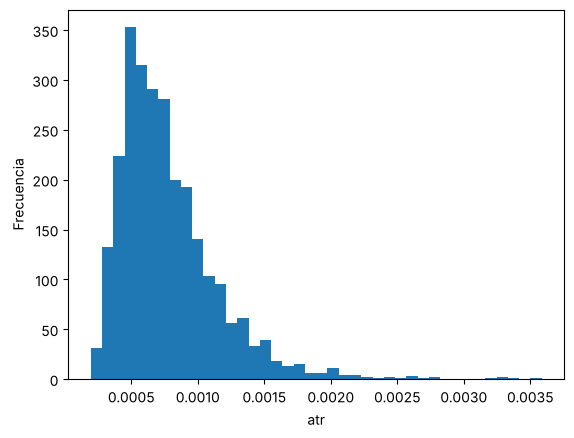

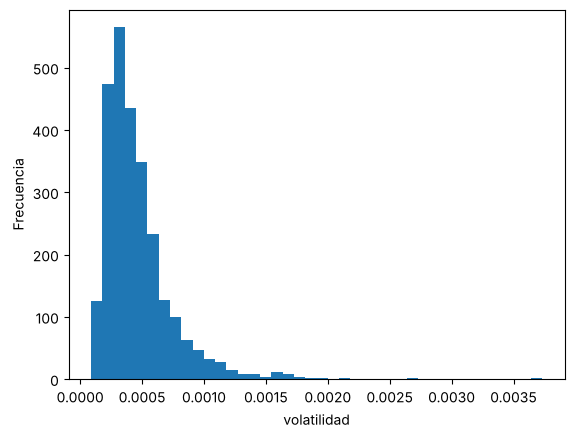

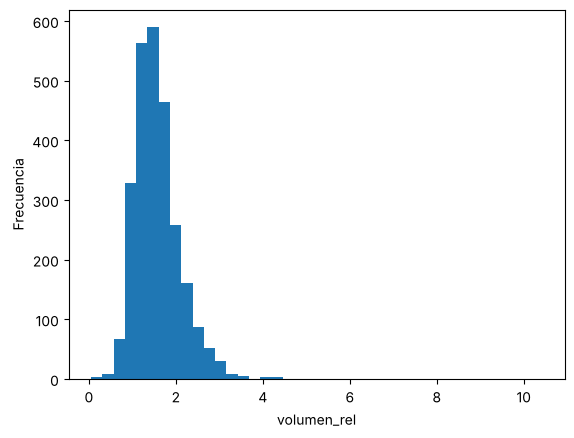

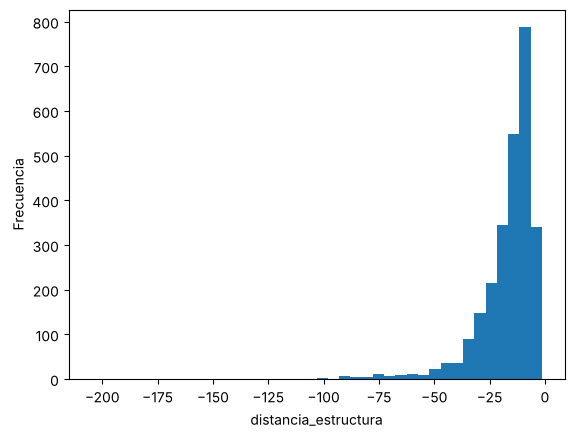

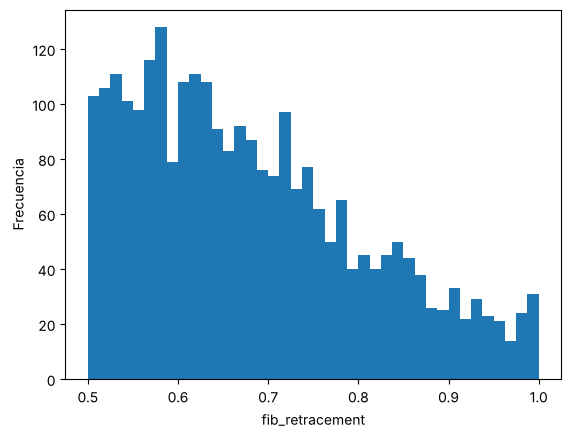

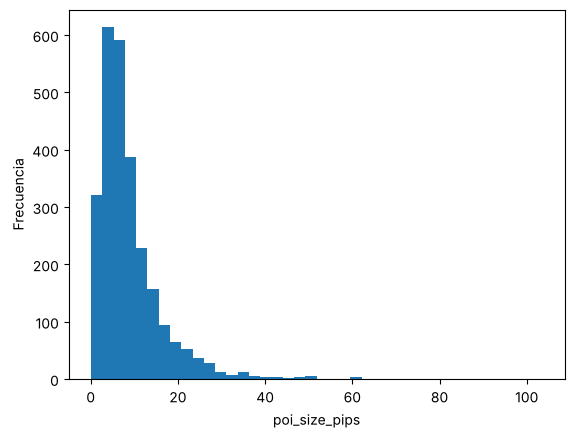

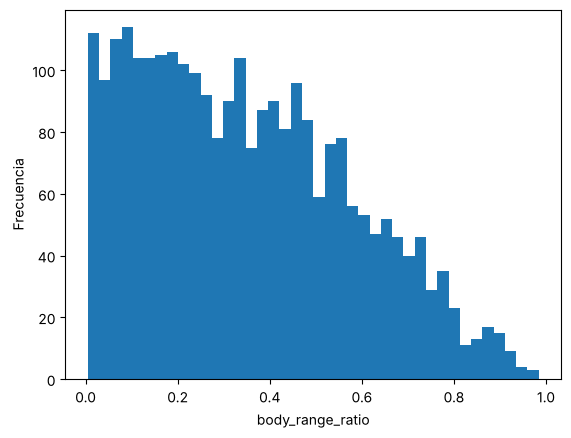

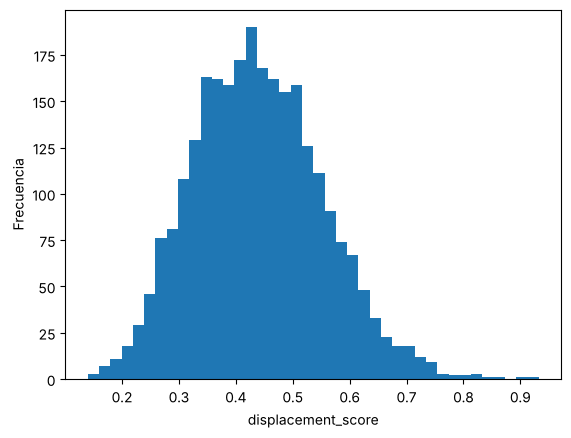

In [6]:
numericas = ["atr", "volatilidad", "volumen_rel", "distancia_estructura", "fib_retracement",
             "poi_size_pips", "body_range_ratio", "displacement_score"]
for col in numericas:
    plt.figure()
    plt.hist(df[col], bins=40)
    plt.xlabel(col)
    plt.ylabel("Frecuencia")

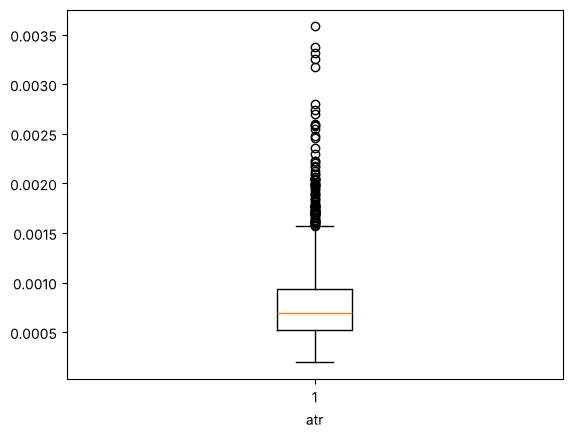

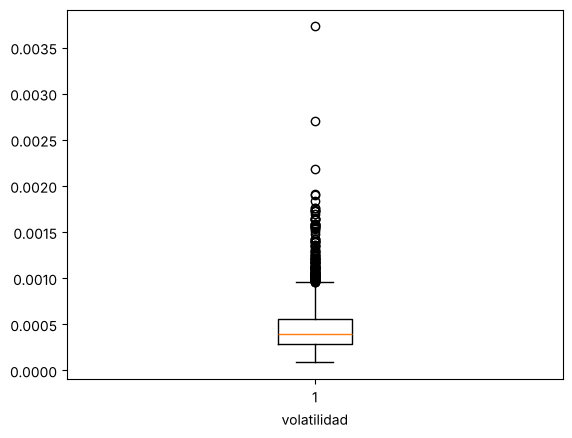

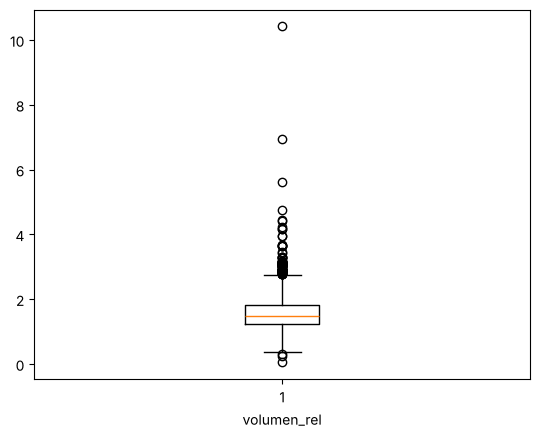

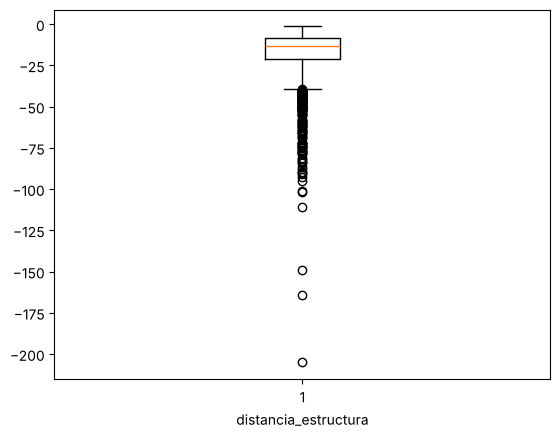

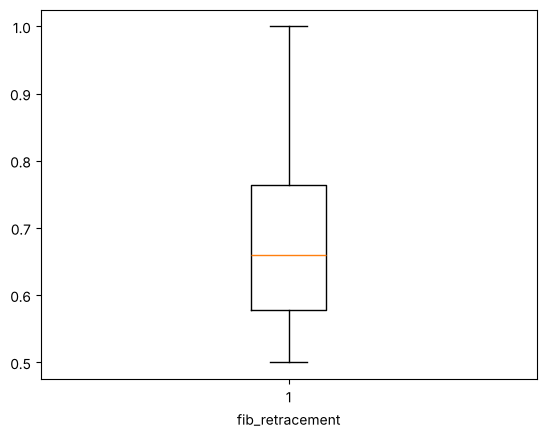

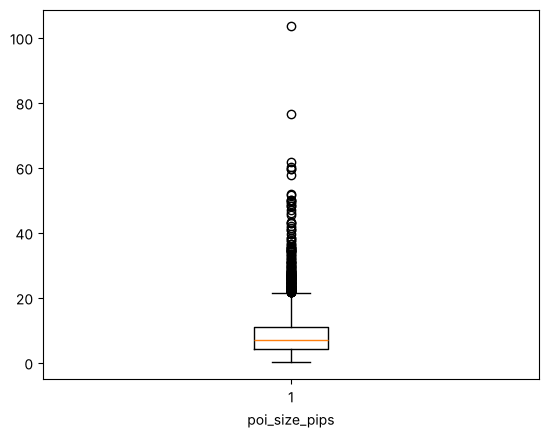

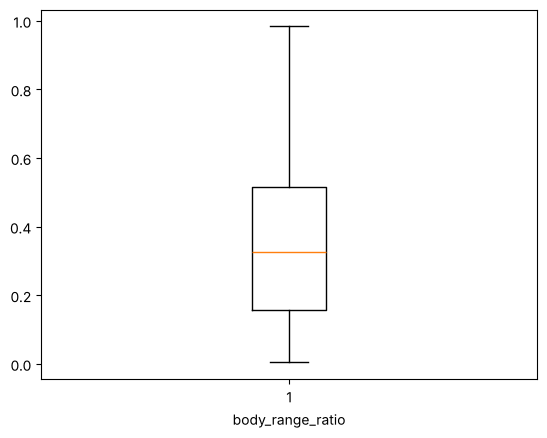

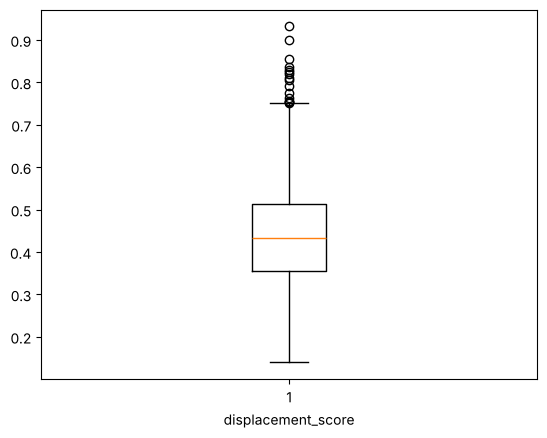

In [7]:
for col in numericas:
    plt.figure()
    plt.boxplot(df[col])
    plt.xlabel(col)

In [8]:
categoricas = ["direccion", "sesion", "cambio_estructura", "h1_alignment"]
for col in categoricas:
    print(col, df[col].unique())

direccion <StringArray>
['venta', 'compra']
Length: 2, dtype: str
sesion <StringArray>
['london_killzone', 'newyork_am_open']
Length: 2, dtype: str
cambio_estructura <StringArray>
['bos_bull', 'bos_bear']
Length: 2, dtype: str
h1_alignment <StringArray>
['aligned', 'counter']
Length: 2, dtype: str


0.3667676003028009


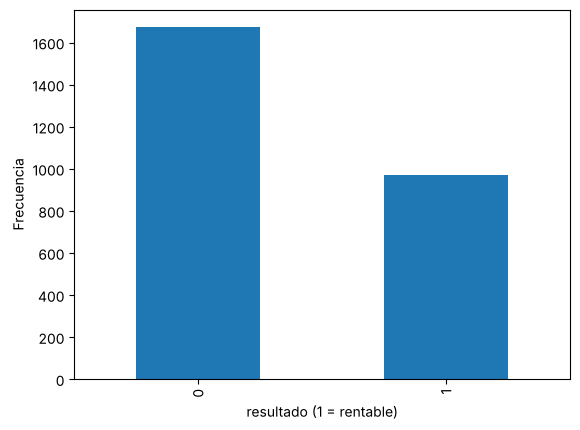

In [9]:
plt.figure()
df["resultado"].value_counts().plot(kind="bar")
plt.xlabel("resultado (1 = rentable)")
plt.ylabel("Frecuencia")
print(df["resultado"].mean())

In [10]:
df.groupby("resultado")[numericas].mean()

,atr,volatilidad,volumen_rel,distancia_estructura,fib_retracement,poi_size_pips,body_range_ratio,displacement_score
resultado,,,,,,,,
0,0.000780,0.000465,1.583650,-16.975134,0.683030,8.641184,0.344733,0.435970
1,0.000768,0.000454,1.581071,-16.952425,0.679058,9.443344,0.357522,0.445569


In [11]:
for col in categoricas + ["poi_type", "poi_state_at_entry", "fib_in_pref_zone"]:
    print(df.groupby(col)["resultado"].agg(["count", "mean"]))
    print()

           count      mean
direccion                 
compra      1310  0.368702
venta       1332  0.364865

                 count      mean
sesion                          
london_killzone   1574  0.375476
newyork_am_open   1068  0.353933

                   count      mean
cambio_estructura                 
bos_bear            1340  0.370896
bos_bull            1302  0.362519

              count      mean
h1_alignment                 
aligned        1196  0.359532
counter        1446  0.372752

          count      mean
poi_type                 
0           889  0.340832
1          1753  0.379920

                    count      mean
poi_state_at_entry                 
0                    1462  0.353625
1                    1180  0.383051

                  count      mean
fib_in_pref_zone                 
0                  1886  0.363733
1                   756  0.374339



In [12]:
anio = pd.to_datetime(df["fecha"]).dt.year
df.groupby(anio)["resultado"].agg(["count", "mean"])

,count,mean
fecha,,
2020,410,0.353659
2021,398,0.396985
2022,408,0.352941
2023,394,0.345178
2024,372,0.389785
2025,373,0.394102
2026,287,0.327526


- 2,642 operaciones y 17 columnas, sin nulos ni duplicados
- Solo el 36.7% de las operaciones son rentables: las clases están desbalanceadas (por eso se usa AUC y `class_weight="balanced"`)
- `atr`, `volatilidad`, `poi_size_pips` y `volumen_rel` tienen colas largas a la derecha y `distancia_estructura` a la izquierda (hasta −205 pips); no se eliminan porque son operaciones reales, y el escalamiento las pone en la misma escala
- Los promedios de las variables numéricas son casi iguales entre operaciones rentables y no rentables, y la tasa de acierto es parecida en todas las categorías (entre 35% y 38%): se espera que sea difícil predecir
- En este periodo `cambio_estructura` solo toma `bos_bull` y `bos_bear`, y `h1_alignment` solo `aligned` y `counter`
- La tasa de acierto por año va de 33% a 40%, sin una tendencia clara

## Limpieza y transformación de variables

In [13]:
df = df.drop_duplicates()
df = df.dropna()

df["fecha"] = pd.to_datetime(df["fecha"])
df = df.sort_values("fecha")
anio = df["fecha"].dt.year

df["direccion"] = df["direccion"].replace({"compra": 1, "venta": 0})

for col in ["sesion", "cambio_estructura", "h1_alignment"]:
    valores = df[col].unique()
    for v in valores[1:]:
        df[col + "_" + v] = (df[col] == v).astype(int)

columnas = list(df.columns)
for col in ["fecha", "sesion", "cambio_estructura", "h1_alignment"]:
    columnas.remove(col)
df = df[columnas]

df = df.astype(float)
print(df.shape)
df.head()

(2642, 16)


,direccion,atr,volatilidad,volumen_rel,distancia_estructura,fib_retracement,fib_in_pref_zone,poi_type,poi_state_at_entry,poi_size_pips,body_range_ratio,displacement_score,resultado,sesion_newyork_am_open,cambio_estructura_bos_bear,h1_alignment_counter
0,0.0,0.000326,0.000237,2.726505,-5.5,0.982143,0.0,1.0,0.0,1.5,0.011628,0.601562,1.0,0.0,0.0,0.0
1,0.0,0.000361,0.000230,1.477003,-4.6,0.589744,0.0,1.0,0.0,1.8,0.285714,0.435607,1.0,0.0,0.0,0.0
2,0.0,0.000290,0.000166,1.527619,-4.9,0.907407,0.0,0.0,1.0,8.7,0.227273,0.373913,0.0,0.0,1.0,1.0
3,0.0,0.000295,0.000160,2.125245,-4.2,0.777778,0.0,1.0,1.0,3.1,0.222222,0.436455,0.0,0.0,1.0,1.0
4,1.0,0.000373,0.000247,2.716287,-5.6,0.636364,1.0,1.0,1.0,4.7,0.361111,0.536998,0.0,0.0,1.0,1.0


- Los datos se ordenan por fecha para que los folds sean bloques de tiempo continuos
- `direccion` se pasa a 1 y 0; `resultado` ya viene como 1 y 0
- `sesion`, `cambio_estructura` y `h1_alignment` se pasan a variables dummy (una columna por categoría menos una)

### Entrenamiento (2020–2024) y prueba (2025–2026)

In [14]:
predictores = list(df.columns)
predictores.remove("resultado")

entrenamiento = df[anio <= 2024]
prueba = df[anio >= 2025]

X = entrenamiento[predictores]
y = entrenamiento["resultado"]
X_test = prueba[predictores]
y_test = prueba["resultado"]

print(X.shape, X_test.shape)
print(y.mean(), y_test.mean())

(1982, 15) (660, 15)
0.36730575176589303 0.36515151515151517


- La optimización de hiperparámetros y la comparación con k-folds se hacen solo con 2020–2024
- 2025–2026 se guarda para la evaluación final, como si fueran operaciones nuevas

## Pipeline

<center><img src="pipeline.png" width="900px"></center>

- El escalamiento va dentro del pipeline, así en cada fold el `StandardScaler` se ajusta solo con los datos de entrenamiento de ese fold y no hay fuga de información hacia el fold de prueba
- Los tres modelos usan exactamente el mismo preprocesamiento y los mismos 10 folds

In [15]:
kf = KFold(n_splits=10)

## Modelos propuestos

En los tres casos la optimización bayesiana sigue el procedimiento visto en clase:
1. Se crea una malla de candidatos en el espacio de hiperparámetros
2. Se evalúan 5 puntos al azar con el AUC promedio de 10 folds sobre 2020–2024
3. Se ajusta un proceso gaussiano con kernel RBF a los puntos evaluados
4. Se evalúa el candidato con mayor $\mu + 2\sigma$ y se repite 20 veces

### 1. Regresión logística con regularización
Hiperparámetros: $\log_{10}(C) \in [-4, 2]$ y `l1_ratio` $\in [0, 1]$ (0 = Ridge, 1 = Lasso).

In [16]:
candidatos_lr = []
for logC in np.linspace(-4, 2, 25):
    for l1 in np.linspace(0, 1, 11):
        candidatos_lr.append([logC, l1])
candidatos_lr = np.array(candidatos_lr)
print(candidatos_lr.shape)

(275, 2)


In [17]:
np.random.seed(42)
idx = np.random.choice(len(candidatos_lr), 5, replace=False)
puntos_lr = candidatos_lr[idx]
auc_lr = []
for p in puntos_lr:
    modelo = make_pipeline(StandardScaler(),
                           LogisticRegression(C=10**p[0], l1_ratio=p[1], penalty="elasticnet",
                                              solver="saga", max_iter=5000, class_weight="balanced"))
    auc = cross_val_score(modelo, X, y, cv=kf, scoring="roc_auc", n_jobs=-1)
    auc_lr.append(auc.mean())

for i in range(20):
    kernel = 1 * RBF(length_scale=1)
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(puntos_lr, auc_lr)
    y_pred, sigma = gp.predict(candidatos_lr, return_std=True)
    y_upper = y_pred + 2*sigma

    x_sig = candidatos_lr[np.argmax(y_upper)]
    modelo = make_pipeline(StandardScaler(),
                           LogisticRegression(C=10**x_sig[0], l1_ratio=x_sig[1], penalty="elasticnet",
                                              solver="saga", max_iter=5000, class_weight="balanced"))
    auc = cross_val_score(modelo, X, y, cv=kf, scoring="roc_auc", n_jobs=-1)
    puntos_lr = np.vstack([puntos_lr, x_sig.reshape(1, -1)])
    auc_lr.append(auc.mean())

mejor_lr = puntos_lr[np.argmax(auc_lr)]
print("Mejor C:", 10**mejor_lr[0], " l1_ratio:", mejor_lr[1], " AUC:", max(auc_lr))

Mejor C: 0.05623413251903491  l1_ratio: 0.5  AUC: 0.5206400127613785


### 2. Máquina de vectores de soporte con kernel RBF
Hiperparámetros: $\log_{10}(C) \in [-2, 2]$ y $\log_{10}(\gamma) \in [-4, 1]$.

In [18]:
candidatos_svm = []
for logC in np.linspace(-2, 2, 21):
    for logG in np.linspace(-4, 1, 21):
        candidatos_svm.append([logC, logG])
candidatos_svm = np.array(candidatos_svm)
print(candidatos_svm.shape)

(441, 2)


In [19]:
np.random.seed(42)
idx = np.random.choice(len(candidatos_svm), 5, replace=False)
puntos_svm = candidatos_svm[idx]
auc_svm = []
for p in puntos_svm:
    modelo = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10**p[0], gamma=10**p[1], class_weight="balanced"))
    auc = cross_val_score(modelo, X, y, cv=kf, scoring="roc_auc", n_jobs=-1)
    auc_svm.append(auc.mean())

for i in range(20):
    kernel = 1 * RBF(length_scale=1)
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(puntos_svm, auc_svm)
    y_pred, sigma = gp.predict(candidatos_svm, return_std=True)
    y_upper = y_pred + 2*sigma

    x_sig = candidatos_svm[np.argmax(y_upper)]
    modelo = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10**x_sig[0], gamma=10**x_sig[1], class_weight="balanced"))
    auc = cross_val_score(modelo, X, y, cv=kf, scoring="roc_auc", n_jobs=-1)
    puntos_svm = np.vstack([puntos_svm, x_sig.reshape(1, -1)])
    auc_svm.append(auc.mean())

mejor_svm = puntos_svm[np.argmax(auc_svm)]
print("Mejor C:", 10**mejor_svm[0], " gamma:", 10**mejor_svm[1], " AUC:", max(auc_svm))

Mejor C: 100.0  gamma: 0.0005623413251903491  AUC: 0.5102544092041955


### 3. Perceptrón multicapa
Dos capas ocultas. Hiperparámetros: neuronas en capa 1 $\in [5, 50]$, neuronas en capa 2 $\in [5, 50]$ y $\log_{10}(\alpha) \in [-5, 0]$.

In [20]:
candidatos_mlp = []
for n1 in range(5, 51, 5):
    for n2 in range(5, 51, 5):
        for logA in np.linspace(-5, 0, 11):
            candidatos_mlp.append([n1, n2, logA])
candidatos_mlp = np.array(candidatos_mlp)
print(candidatos_mlp.shape)

(1100, 3)


In [21]:
np.random.seed(42)
idx = np.random.choice(len(candidatos_mlp), 5, replace=False)
puntos_mlp = candidatos_mlp[idx]
auc_mlp = []
for p in puntos_mlp:
    modelo = make_pipeline(StandardScaler(),
                           MLPClassifier(hidden_layer_sizes=(int(p[0]), int(p[1])), alpha=10**p[2],
                                         max_iter=1000, random_state=42))
    auc = cross_val_score(modelo, X, y, cv=kf, scoring="roc_auc", n_jobs=-1)
    auc_mlp.append(auc.mean())

for i in range(20):
    kernel = 1 * RBF(length_scale=1)
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(puntos_mlp, auc_mlp)
    y_pred, sigma = gp.predict(candidatos_mlp, return_std=True)
    y_upper = y_pred + 2*sigma

    x_sig = candidatos_mlp[np.argmax(y_upper)]
    modelo = make_pipeline(StandardScaler(),
                           MLPClassifier(hidden_layer_sizes=(int(x_sig[0]), int(x_sig[1])), alpha=10**x_sig[2],
                                         max_iter=1000, random_state=42))
    auc = cross_val_score(modelo, X, y, cv=kf, scoring="roc_auc", n_jobs=-1)
    puntos_mlp = np.vstack([puntos_mlp, x_sig.reshape(1, -1)])
    auc_mlp.append(auc.mean())

mejor_mlp = puntos_mlp[np.argmax(auc_mlp)]
print("Mejor capas:", (int(mejor_mlp[0]), int(mejor_mlp[1])), " alpha:", 10**mejor_mlp[2], " AUC:", max(auc_mlp))

Mejor capas: (50, 30)  alpha: 1.0  AUC: 0.5432765118376389


### AUC en cada evaluación de la optimización bayesiana

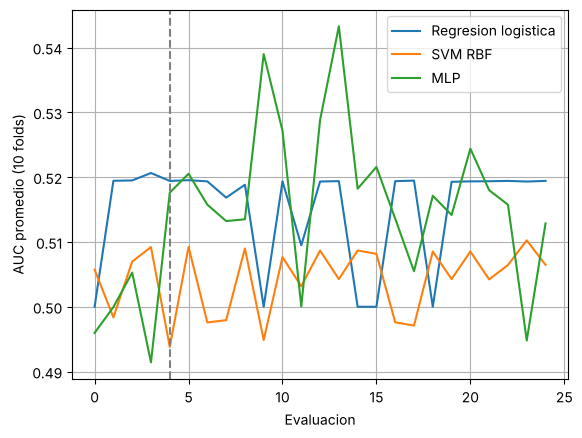

In [22]:
plt.figure()
plt.plot(auc_lr, label="Regresion logistica")
plt.plot(auc_svm, label="SVM RBF")
plt.plot(auc_mlp, label="MLP")
plt.axvline(4, color="gray", linestyle="--")
plt.xlabel("Evaluacion")
plt.ylabel("AUC promedio (10 folds)")
plt.legend()
plt.grid()

- Las primeras 5 evaluaciones (antes de la línea punteada) son al azar; después las elige el proceso gaussiano

## Ajuste de modelos y comparación

Con los mejores hiperparámetros de cada modelo se repite la validación cruzada de 10 folds sobre 2020–2024 y se reporta la media y la desviación estándar del ROC-AUC, junto con precisión, recall, F1 y accuracy.

In [23]:
modelo_lr = make_pipeline(StandardScaler(),
                          LogisticRegression(C=10**mejor_lr[0], l1_ratio=mejor_lr[1], penalty="elasticnet",
                                             solver="saga", max_iter=5000, class_weight="balanced"))
modelo_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10**mejor_svm[0], gamma=10**mejor_svm[1],
                                                 class_weight="balanced"))
modelo_mlp = make_pipeline(StandardScaler(),
                           MLPClassifier(hidden_layer_sizes=(int(mejor_mlp[0]), int(mejor_mlp[1])),
                                         alpha=10**mejor_mlp[2], max_iter=1000, random_state=42))

modelos = [modelo_lr, modelo_svm, modelo_mlp]
nombres = ["Regresion logistica", "SVM RBF", "MLP"]
metricos = ["roc_auc", "precision", "recall", "f1", "accuracy"]

resultados = pd.DataFrame(index=nombres)
auc_folds = []
for m in metricos:
    media = []
    std = []
    for modelo in modelos:
        score = cross_val_score(modelo, X, y, cv=kf, scoring=m, n_jobs=-1)
        media.append(score.mean())
        std.append(np.std(score))
        if m == "roc_auc":
            auc_folds.append(score)
    resultados[m + " media"] = media
    resultados[m + " std"] = std
resultados

,roc_auc media,roc_auc std,precision media,precision std,recall media,recall std,f1 media,f1 std,accuracy media,accuracy std
Regresion logistica,0.520651,0.037037,0.377440,0.058922,0.491425,0.051863,0.424983,0.049815,0.514169,0.031464
SVM RBF,0.510254,0.050472,0.371747,0.054944,0.468898,0.075702,0.412886,0.056867,0.515682,0.030554
MLP,0.543277,0.049613,0.416926,0.074802,0.268580,0.044699,0.323256,0.046568,0.589310,0.042527


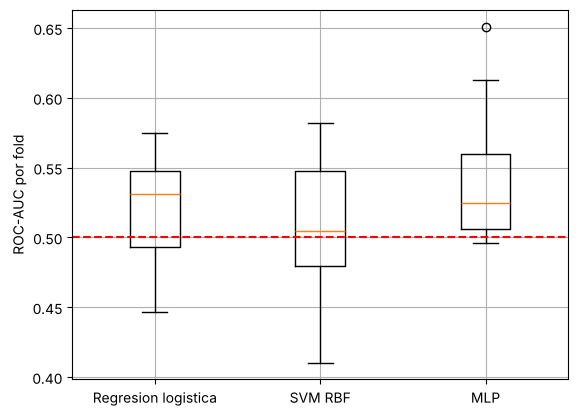

In [24]:
plt.figure()
plt.boxplot(auc_folds)
plt.xticks([1, 2, 3], nombres)
plt.axhline(0.5, color="red", linestyle="--")
plt.ylabel("ROC-AUC por fold")
plt.grid()

- El MLP tiene el AUC promedio más alto (0.543), seguido de la regresión logística (0.521) y la SVM (0.510)
- Las desviaciones (0.04–0.05) son del mismo tamaño que las diferencias entre modelos, así que los tres están muy cerca y todos apenas por encima de 0.5
- La precisión (0.37–0.42) es solo un poco mayor que el 36.7% de operaciones rentables, es decir, el modelo mejora poco sobre tomar todas las operaciones
- La optimización bayesiana eligió regularización fuerte (C = 0.056 en la logística, alpha = 1 en el MLP, el máximo del rango): los modelos más simples funcionan mejor porque hay poca señal y mucho ruido

### Evaluación en el periodo de prueba (2025–2026)

In [25]:
modelo_lr.fit(X, y)
modelo_svm.fit(X, y)
modelo_mlp.fit(X, y)

puntaje_lr = modelo_lr.predict_proba(X_test)[:, 1]
puntaje_svm = modelo_svm.decision_function(X_test)
puntaje_mlp = modelo_mlp.predict_proba(X_test)[:, 1]

auc_prueba = [roc_auc_score(y_test, puntaje_lr), roc_auc_score(y_test, puntaje_svm),
              roc_auc_score(y_test, puntaje_mlp)]
resultados["roc_auc prueba"] = auc_prueba
resultados[["roc_auc media", "roc_auc std", "roc_auc prueba"]]

,roc_auc media,roc_auc std,roc_auc prueba
Regresion logistica,0.520651,0.037037,0.549689
SVM RBF,0.510254,0.050472,0.520544
MLP,0.543277,0.049613,0.551124


- La SVM no da probabilidades sino una distancia a la frontera (`decision_function`); para el AUC basta porque solo se necesita ordenar las operaciones
- En 2025–2026, que los modelos nunca vieron, el AUC es 0.550 (logística), 0.521 (SVM) y 0.551 (MLP)
- Es parecido o un poco mayor que en validación cruzada, así que la poca señal que encontraron se mantiene fuera de muestra y no es sobreajuste

### Utilidad para la estrategia

Se ordenan las operaciones de 2025–2026 según el puntaje de cada modelo y se compara la tasa de acierto y la ganancia neta promedio (en pips, después de costos) de todas las operaciones contra la mitad y la cuarta parte con mayor puntaje. La ganancia de cada operación viene de `results/eurusd_metadata.csv` y solo se usa para evaluar, no como predictor.

In [26]:
meta = pd.read_csv("../results/eurusd_metadata.csv")
meta["fecha"] = pd.to_datetime(meta["fecha"])
meta = meta.sort_values("fecha")
pips_test = meta[meta["fecha"].dt.year >= 2025]["net_pips"].values

puntajes = [puntaje_lr, puntaje_svm, puntaje_mlp]
filas = []
for i in range(3):
    for q in [0, 0.5, 0.75]:
        corte = np.quantile(puntajes[i], q)
        filtro = puntajes[i] >= corte
        filas.append([nombres[i], str(int((1 - q) * 100)) + "% con mayor puntaje", filtro.sum(),
                      y_test[filtro].mean(), pips_test[filtro].mean(), pips_test[filtro].sum()])
utilidad = pd.DataFrame(filas, columns=["Modelo", "Operaciones tomadas", "n", "Tasa de acierto",
                                        "Pips netos promedio", "Pips netos totales"])
utilidad

,Modelo,Operaciones tomadas,n,Tasa de acierto,Pips netos promedio,Pips netos totales
0,Regresion logistica,100% con mayor puntaje,660,0.365152,-1.123788,-741.7
1,Regresion logistica,50% con mayor puntaje,330,0.409091,-0.898182,-296.4
2,Regresion logistica,25% con mayor puntaje,165,0.412121,-1.448485,-239.0
3,SVM RBF,100% con mayor puntaje,660,0.365152,-1.123788,-741.7
4,SVM RBF,50% con mayor puntaje,330,0.393939,-1.235152,-407.6
5,SVM RBF,25% con mayor puntaje,165,0.400000,-1.362424,-224.8
6,MLP,100% con mayor puntaje,660,0.365152,-1.123788,-741.7
7,MLP,50% con mayor puntaje,330,0.396970,-0.562424,-185.6
8,MLP,25% con mayor puntaje,165,0.400000,-1.374545,-226.8


- Tomando todas las operaciones de 2025–2026, la tasa de acierto es 36.5% y se pierden 1.12 pips por operación
- Quedándose con la mitad de mayor puntaje, la tasa de acierto sube a 39–41% y la pérdida baja (a −0.56 pips con el MLP y −0.90 con la logística)
- Con la cuarta parte de mayor puntaje ya no mejora más: la señal es débil y no alcanza para separar un grupo claramente rentable
- El modelo ayuda a ordenar las operaciones, pero no lo suficiente para que la estrategia gane dinero después de costos

## Conclusiones

- **Dataset (objetivo 1):** el dataset de 2,642 operaciones está limpio y sin información del futuro, pero sus variables tienen poca relación con el resultado: las medias y tasas de acierto son casi iguales entre grupos
- **Pipeline (objetivo 2):** el mismo preprocesamiento con escalamiento dentro de cada fold permitió comparar los tres modelos en igualdad y sin fuga de información
- **Modelos y optimización (objetivo 3):** la optimización bayesiana con procesos gaussianos encontró los hiperparámetros con 25 evaluaciones por modelo y en los tres casos prefirió modelos muy regularizados, lo que indica poca señal en los datos
- **Comparación (objetivo 4):** el MLP fue el mejor en validación cruzada (AUC 0.543 ± 0.050) y en prueba (0.551), muy cerca de la regresión logística (0.550 en prueba). Que el modelo no lineal no supere claramente al lineal indica que no hay patrones complejos que aprovechar. Todos quedan apenas arriba de 0.5
- **Utilidad (objetivo 5):** filtrar con el modelo sube la tasa de acierto de 36.5% a cerca de 40% y reduce la pérdida promedio, pero la estrategia sigue perdiendo después de costos
- **Conclusión general:** con la información disponible al momento de entrar, la rentabilidad de una operación de esta estrategia es casi impredecible. Para mejorar habría que agregar variables de otro tipo (noticias económicas, spread real, contexto de temporalidades mayores) o revisar las reglas de la estrategia

## Referencias

- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
- Bradley, A. P. (1997). The use of the area under the ROC curve in the evaluation of machine learning algorithms. *Pattern Recognition, 30*(7), 1145–1159. https://doi.org/10.1016/S0031-3203(96)00142-2
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0
- López de Prado, M. (2018). *Advances in financial machine learning*. Wiley.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press.
- Snoek, J., Larochelle, H., & Adams, R. P. (2012). Practical Bayesian optimization of machine learning algorithms. *Advances in Neural Information Processing Systems, 25*, 2951–2959.
- Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B, 67*(2), 301–320. https://doi.org/10.1111/j.1467-9868.2005.00503.x